<a href="https://colab.research.google.com/github/zegavibiano22-tech/WiFi-CSI-CrossDomain-Sensing/blob/main/notebooks/00_eda_bvp_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

File .mat yang ada:
 - /content/user1-1-1-1-1-1-1e-07-100-20-100000-L0.mat
Variabel: velocity_spectrum_ro | bentuk: (20, 20, 20)


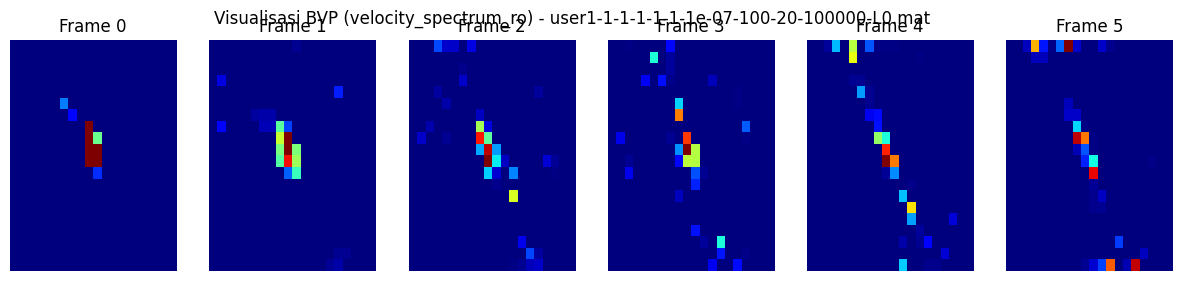

In [2]:
import glob
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

files = sorted(glob.glob('/content/**/*.mat', recursive=True))
print("File .mat yang ada:")
for f in files:
    print(" -", f)
assert files, "Tidak ada file .mat. Upload file atau jalankan ulang sel setup (git clone)."

path = files[0]                      # ganti angka 0 untuk memilih file lain
mat = sio.loadmat(path)
key_utama = [k for k in mat if not k.startswith("__")][0]   # biasanya 'velocity_spectrum_ro'
matriks = mat[key_utama]
print("Variabel:", key_utama, "| bentuk:", matriks.shape)

# Tampilkan 6 frame waktu pertama (bentuk data: 20 x 20 x T)
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i, ax in enumerate(axes):
    ax.imshow(matriks[:, :, i], aspect='auto', cmap='jet')
    ax.set_title(f"Frame {i}")
    ax.axis('off')
plt.suptitle(f"Visualisasi BVP ({key_utama}) - {path.split('/')[-1]}")
plt.show()

In [3]:
import torch
from torch.utils.data import Dataset, DataLoader
import re

def parse_filename(filename):
    # Mengambil ID gesture dan environment dari nama file Widar 3.0
    parts = filename.split('-')

    # Ekstraksi label gesture dan environment
    user_id = int(re.search(r'\d+', parts[0]).group())
    gesture_label = int(parts[1]) - 1     # Class target (misal: 0-5)
    env_label = int(parts[2]) - 1         # Domain target (misal: 0-2)

    return gesture_label, env_label

# Cek parse nama file sampel
sample_name = 'user1-1-1-1-1-1e-07-100-20-100000-L0.mat'
g_label, e_label = parse_filename(sample_name)

# Konversi matriks BVP ke PyTorch Tensor
tensor_bvp = torch.tensor(matriks, dtype=torch.float32)

print(f"File: {sample_name}")
print(f"Parsed Gesture Label (Y) : {g_label}")
print(f"Parsed Domain/Env (D)    : {e_label}")
print(f"Shape Tensor PyTorch     : {tensor_bvp.shape}")

File: user1-1-1-1-1-1e-07-100-20-100000-L0.mat
Parsed Gesture Label (Y) : 0
Parsed Domain/Env (D)    : 0
Shape Tensor PyTorch     : torch.Size([20, 20, 20])


In [4]:
import os
import glob
import torch
from torch.utils.data import Dataset, DataLoader
import scipy.io as sio

class WidarBVPDataset(Dataset):
    def __init__(self, file_paths):
        self.file_paths = file_paths

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        file_path = self.file_paths[idx]
        filename = os.path.basename(file_path)

        # Load matriks BVP
        data = sio.loadmat(file_path)
        matriks = data['velocity_spectrum_ro']

        # Parse label gesture (Y) & domain (D)
        parts = filename.split('-')
        gesture_label = int(parts[1]) - 1
        env_label = int(parts[2]) - 1

        # Convert ke PyTorch Tensor
        # Format Tensor: (Channel=1, Time=20, Height=20, Width=20) untuk input CNN
        tensor_bvp = torch.tensor(matriks, dtype=torch.float32).unsqueeze(0)

        return tensor_bvp, torch.tensor(gesture_label, dtype=torch.long), torch.tensor(env_label, dtype=torch.long)

# Testing DatasetLoader dengan file sampel yang ada
sample_files = glob.glob('*.mat')
dataset = WidarBVPDataset(sample_files)
dataloader = DataLoader(dataset, batch_size=1, shuffle=True)

# Cek 1 batch data
for bvp_batch, y_batch, d_batch in dataloader:
    print("Batch BVP Shape     :", bvp_batch.shape)  # Expect: [1, 1, 20, 20, 20]
    print("Batch Gesture Label :", y_batch)
    print("Batch Domain Label  :", d_batch)
    break

Batch BVP Shape     : torch.Size([1, 1, 20, 20, 20])
Batch Gesture Label : tensor([0])
Batch Domain Label  : tensor([0])
